In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import joblib
import shap

DATA_PATH = Path("../data/processed")
MODEL_PATH = Path("../outputs/models")
FIG_PATH = Path("../outputs/figures")
FIG_PATH.mkdir(parents=True, exist_ok=True)

train = pd.read_csv(DATA_PATH / "train_processed.csv")
test = pd.read_csv(DATA_PATH / "test_processed.csv")
X_train, y_train = train.drop(columns="Outcome"), train["Outcome"]
X_test, y_test = test.drop(columns="Outcome"), test["Outcome"]

# Explain whichever model notebook 04 actually selected — SHAP TreeExplainer works for
# both XGBoost and the K-Means + Random Forest candidate.
selection_metadata = joblib.load(MODEL_PATH / "selection_metadata.pkl")
selected_name = selection_metadata["selected_model"]
print("Explaining selected model:", selected_name)

if selected_name.startswith("XGBoost"):
    model = joblib.load(MODEL_PATH / "xgboost_final_model.pkl")
    X_explain = X_test
else:
    model = joblib.load(MODEL_PATH / "kmeans_rf_final_model.pkl")
    X_explain = pd.read_csv(DATA_PATH / "X_test_kmeans_features.csv")

best_xgb = model  # kept as best_xgb for compatibility with the rest of this notebook
X_test = X_explain


Explaining selected model: XGBoost


**Build SHAP explainer (TreeExplainer — exact and fast for XGBoost)**

In [2]:
explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer.shap_values(X_test)


**Global feature importance — SHAP summary (beeswarm)**

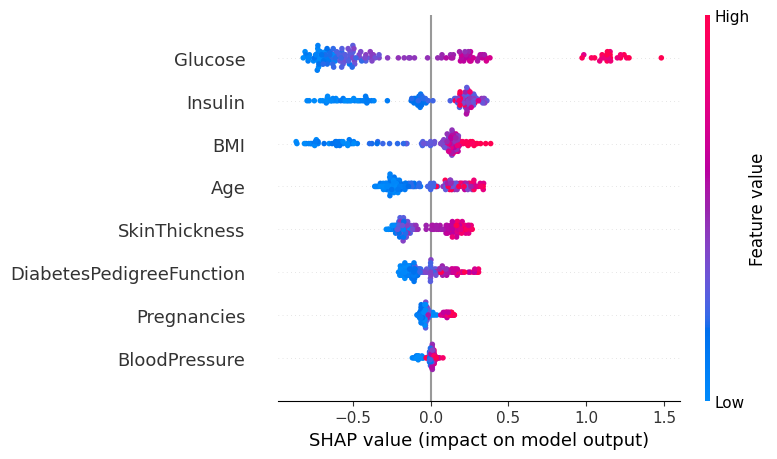

In [3]:
shap.summary_plot(shap_values, X_test, show=False)
plt.tight_layout()
plt.savefig(FIG_PATH / "shap_summary_beeswarm.png", dpi=120, bbox_inches="tight")
plt.show()


**Global feature importance — mean |SHAP value| bar chart**

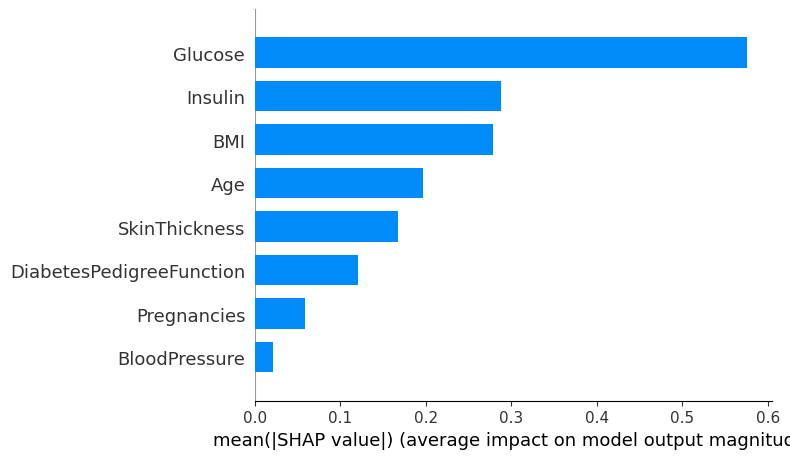

In [4]:
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)
plt.tight_layout()
plt.savefig(FIG_PATH / "shap_summary_bar.png", dpi=120, bbox_inches="tight")
plt.show()


**Local explanation — one correctly predicted diabetic patient**

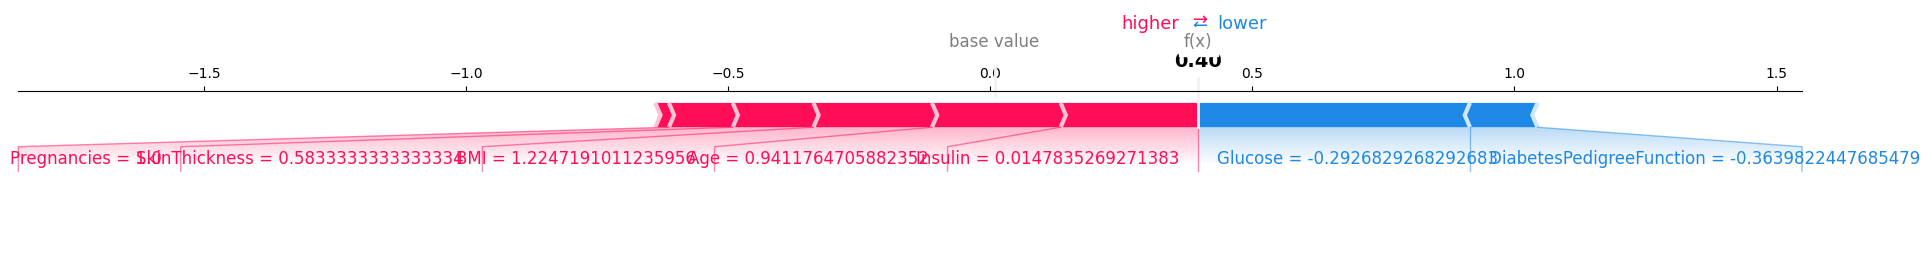

Patient row:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
6,1.0,-0.292683,1.75,0.583333,0.014784,1.224719,-0.363982,0.941176


In [5]:
y_pred = best_xgb.predict(X_test)
idx_candidates = X_test.index[(y_test.values == 1) & (y_pred == 1)]
idx = idx_candidates[0]

shap.force_plot(
    explainer.expected_value,
    shap_values[idx],
    X_test.iloc[idx],
    matplotlib=True,
    show=False
)
plt.tight_layout()
plt.savefig(FIG_PATH / "shap_force_plot_example.png", dpi=120, bbox_inches="tight")
plt.show()

print("Patient row:")
X_test.iloc[[idx]]


**Local explanation — waterfall view (often clearer than force plot)**

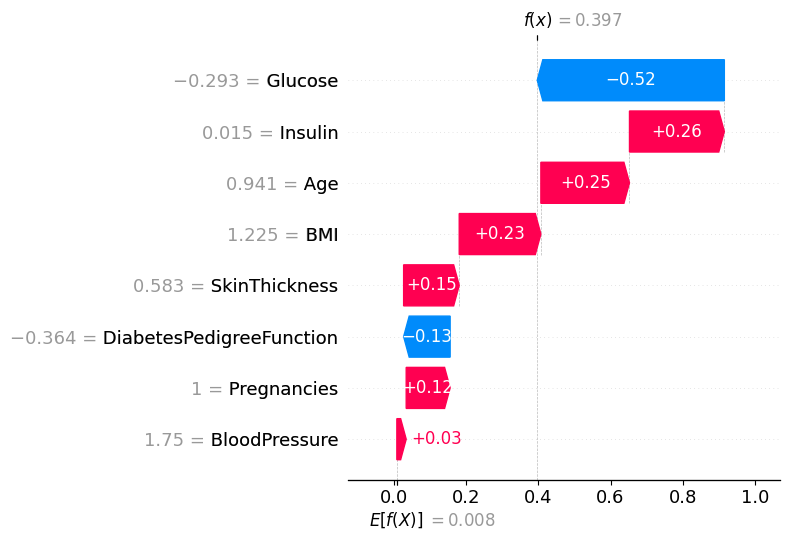

In [6]:
shap_exp = shap.Explanation(
    values=shap_values[idx],
    base_values=explainer.expected_value,
    data=X_test.iloc[idx],
    feature_names=X_test.columns.tolist()
)
shap.plots.waterfall(shap_exp, show=False)
plt.tight_layout()
plt.savefig(FIG_PATH / "shap_waterfall_example.png", dpi=120, bbox_inches="tight")
plt.show()


**Dependence plot — how Glucose drives predictions, and its interaction with BMI**

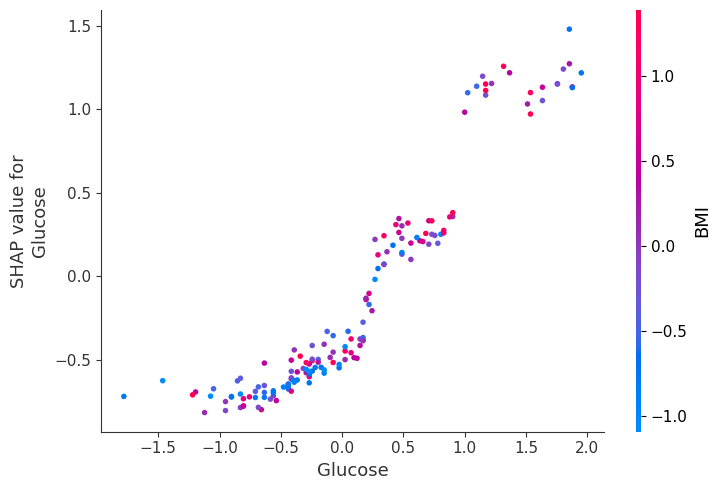

In [7]:
shap.dependence_plot("Glucose", shap_values, X_test, interaction_index="BMI", show=False)
plt.tight_layout()
plt.savefig(FIG_PATH / "shap_dependence_glucose_bmi.png", dpi=120, bbox_inches="tight")
plt.show()
